# LifeGuard-RL XJTU charge-only SOH reliability

Test whether using details of the charging taper improves the existing late-charge estimate. The charging quality check can fall back to recent normal estimates or mark a run of unusual readings as uncertain.

1. Attach **lifeguard_soh_results.zip** from the first SOH benchmark or **lifeguard_soh_validation_results.zip** from the second. An extracted folder with **cycle_quality.csv** and **cycle_features.csv** works too.
2. Run all cells on **Kaggle CPU**. The notebook reads the saved cycle tables.
3. Download **lifeguard_soh_reliability_results.zip** with the metrics, coverage, cell splits, and cycle 390 comparison.

[BatteryLife v12 release](https://zenodo.org/records/21149533)

In [1]:
INPUT_ROOT = None
SOH_RESULTS_PATH = None  # Set to a SOH ZIP or extracted folder if needed.
OUTPUT_ROOT = None
SEED = 42

from collections import deque
from importlib.metadata import version
import json
from pathlib import Path, PurePosixPath
from tempfile import TemporaryDirectory
from zipfile import ZIP_DEFLATED, ZipFile

from IPython.display import Image, Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import HuberRegressor, LinearRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

if INPUT_ROOT is None:
    if Path("/kaggle/input").is_dir():
        INPUT_ROOT = "/kaggle/input"
    elif Path.cwd().name == "notebooks":
        INPUT_ROOT = Path.cwd().parent
    else:
        INPUT_ROOT = Path.cwd()
if OUTPUT_ROOT is None:
    OUTPUT_ROOT = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd() / "outputs"
INPUT_ROOT = Path(INPUT_ROOT).expanduser().resolve()
OUTPUT_ROOT = Path(OUTPUT_ROOT).expanduser().resolve()
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError(f"Input folder does not exist: {INPUT_ROOT}")

## Model inputs and charge checks

The reference model fits a line from total charge delivered by the late-taper cutoff to measured SOH. The second model starts with total charge divided by nominal capacity and learns a Huber correction from taper duration and the fraction of total charge delivered during taper. Discharge SOH is used as a target during training and to calculate held-out errors. Scaling and fitting use training cells only.

The flag compares charge, total charge duration and taper duration against the cell's previous ten charge readings. For a single unusual reading, the guarded method may use the median of three prior normal predictions from that cell. Repeated unusual readings or insufficient recent history give an uncertain result. A normal reading uses its current estimate directly.

[Huber regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.HuberRegressor.html)

In [2]:
KEY = ["cell_id", "cycle"]
FIXED_CELLS = {
    f"XJTU_{rate}C_battery-{number}": rate
    for rate, count in ((2, 8), (3, 15))
    for number in range(1, count + 1)
}
NOMINAL_AH = 2.0
HISTORY_SIZE = 10
MIN_FLAG_HISTORY = 5
MAD_MULTIPLIER = 6.0
FLAG_FLOORS = {"prefix_charge_ah": 0.08, "charge_duration_s": 120.0, "taper_duration_s": 120.0}
CHARGE_FIELDS = [*FLAG_FLOORS, "taper_charge_ah"]
RESIDUAL_FIELDS = ["taper_duration_s", "taper_charge_fraction"]
RESULT_ARCHIVES = ("lifeguard_soh_validation_results.zip", "lifeguard_soh_results.zip")
OUTLIER_CELL, OUTLIER_CYCLE = "XJTU_2C_battery-2", 390


def one_match(matches, description):
    matches = sorted(set(matches))
    if len(matches) != 1:
        raise ValueError(f"Expected one {description}, found {len(matches)}. Set SOH_RESULTS_PATH.")
    return matches[0]


def locate_soh_export(root):
    if SOH_RESULTS_PATH is not None:
        return Path(SOH_RESULTS_PATH).expanduser().resolve()
    for filename in RESULT_ARCHIVES:
        matches = list(root.rglob(filename))
        if matches:
            return one_match(matches, filename)
    folders = [p.parent for p in root.rglob("cycle_quality.csv") if (p.parent / "cycle_features.csv").is_file()]
    return one_match(folders, "folder with both cycle tables")


def load_cycles(source):
    names = ("cycle_quality.csv", "cycle_features.csv")
    if source.is_dir():
        quality, features = (pd.read_csv(source / name) for name in names)
    else:
        with ZipFile(source) as archive:
            tables = []
            for name in names:
                member = one_match([member for member in archive.namelist() if PurePosixPath(member).name == name], name)
                with archive.open(member) as stream:
                    tables.append(pd.read_csv(stream))
        quality, features = tables

    late = {f"late_taper_{name}": name for name in CHARGE_FIELDS}
    if all(name in features.columns for name in late):
        features = features.rename(columns=late)
    quality = quality[KEY + ["charge_rate_c", "discharge_capacity_ah"]].copy()
    features = features[KEY + CHARGE_FIELDS].copy()
    for frame in (quality, features):
        if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
            raise ValueError("The export must contain complete, unique cell and cycle keys.")
    if set(quality.cell_id) != set(FIXED_CELLS) or not quality.charge_rate_c.eq(quality.cell_id.map(FIXED_CELLS)).all():
        raise ValueError("Expected all 23 fixed-protocol XJTU cells with their documented rates.")
    feature_keys = features.merge(quality[KEY], on=KEY, how="left", indicator=True, validate="one_to_one")
    if not feature_keys["_merge"].eq("both").all():
        raise ValueError("Every charging feature row must have a matching cycle key in cycle_quality.csv.")
    if not np.isfinite(quality.discharge_capacity_ah).all() or not quality.discharge_capacity_ah.gt(0).all():
        raise ValueError("The XJTU evaluation requires finite, positive discharge capacity labels.")
    for cell, frame in quality.groupby("cell_id"):
        if not np.array_equal(np.sort(frame.cycle), np.arange(1, len(frame) + 1)):
            raise ValueError(f"Unexpected cycle numbers in {cell}.")
    quality["observed_soh_pct"] = 100.0 * quality.discharge_capacity_ah / NOMINAL_AH

    flags = flag_charge_traces(features)
    cycles = quality.merge(flags, on=KEY, how="left", validate="one_to_one").sort_values(KEY).reset_index(drop=True)
    cycles["trace_flagged"] = cycles.trace_flagged.eq(True)
    cycles["reference_ready"] = cycles.reference_ready.eq(True)
    values = cycles[CHARGE_FIELDS]
    cycles["input_valid"] = (
        np.isfinite(values).all(axis=1) & cycles.prefix_charge_ah.gt(0) & cycles.charge_duration_s.gt(0)
        & cycles.taper_duration_s.ge(0) & cycles.taper_duration_s.le(cycles.charge_duration_s)
        & cycles.taper_charge_ah.ge(0) & cycles.taper_charge_ah.le(cycles.prefix_charge_ah)
    )
    cycles["taper_charge_fraction"] = cycles.taper_charge_ah.div(cycles.prefix_charge_ah.where(cycles.input_valid))
    return cycles

In [3]:
def flag_charge_traces(features):
    by_cell = []
    for _, frame in features.groupby("cell_id", sort=False):
        frame = frame.sort_values("cycle").copy()
        marks = []
        for feature, floor in FLAG_FLOORS.items():
            values = frame[feature]
            valid = np.isfinite(values) & (values.ge(0) if feature == "taper_duration_s" else values.gt(0))
            # The shift keeps the current reading out of its own reference window.
            prior = values.where(valid).shift().rolling(HISTORY_SIZE, min_periods=MIN_FLAG_HISTORY)
            center = prior.median()
            mad = prior.apply(lambda window: np.nanmedian(np.abs(window - np.nanmedian(window))), raw=True)
            limit = (MAD_MULTIPLIER * 1.4826 * mad).clip(lower=floor)
            frame[f"{feature}_prior_median"] = center
            frame[f"{feature}_deviation_limit"] = limit
            flag = f"{feature}_flag"
            frame[flag] = ~valid | (values.sub(center).abs() > limit)
            marks.append(flag)
        frame["trace_flagged"] = frame[marks].any(axis=1)
        frame["reference_ready"] = frame[[f"{k}_prior_median" for k in FLAG_FLOORS]].notna().all(axis=1)
        by_cell.append(frame)
    return pd.concat(by_cell, ignore_index=True)

In [4]:
CURRENT = "current"
FALLBACK = "fallback"
UNCERTAIN = "uncertain_abnormal"
MISSING = "missing_charge_features"
FALLBACK_COUNT = 3


def guarded_estimates(rows, predictions):
    if rows.duplicated(KEY).any() or not rows.index.is_unique:
        raise ValueError("Guarding requires one row per cell and cycle.")
    estimates = pd.Series(predictions, index=rows.index, dtype=float)
    values = pd.Series(np.nan, index=rows.index)
    status = pd.Series(MISSING, index=rows.index, dtype=object)
    for _, cell in rows.sort_values(KEY).groupby("cell_id", sort=False):
        recent_clean = deque(maxlen=FALLBACK_COUNT)
        previous_status, previous_cycle = None, None
        for index, cycle, flagged in cell[["cycle", "trace_flagged"]].itertuples():
            raw = estimates.at[index]
            if np.isfinite(raw):
                if not flagged:
                    values.at[index] = raw
                    status.at[index] = CURRENT
                    recent_clean.append((cycle, raw))
                elif (previous_status == CURRENT and previous_cycle == cycle - 1
                      and len(recent_clean) == FALLBACK_COUNT and recent_clean[0][0] >= cycle - HISTORY_SIZE):
                    values.at[index] = float(np.median([value for _, value in recent_clean]))
                    status.at[index] = FALLBACK
                else:
                    status.at[index] = UNCERTAIN
            previous_status, previous_cycle = status.at[index], cycle
    return values, status


def check_guard_causality():
    rows = pd.DataFrame({
        "cell_id": ["a"] * 9 + ["b"] * 2,
        "cycle": [*range(1, 10), 1, 2],
        "trace_flagged": [False, False, False, True, True, False, False, True, False, True, False],
    })
    estimates = np.array([85.0, 84.0, 83.0, 96.0, 98.0, 80.0, np.nan, 95.0, 77.0, 91.0, 79.0])
    values, status = guarded_estimates(rows, estimates)
    assert status.tolist() == [CURRENT, CURRENT, CURRENT, FALLBACK, UNCERTAIN, CURRENT, MISSING,
                               UNCERTAIN, CURRENT, UNCERTAIN, CURRENT]
    assert values.iloc[3] == 84.0 and np.isnan(values.iloc[4])
    assert values.iloc[5] == 80.0 and values.iloc[8] == 77.0
    partial, partial_status = guarded_estimates(rows.iloc[:4], estimates[:4])
    pd.testing.assert_series_equal(partial, values.iloc[:4])
    pd.testing.assert_series_equal(partial_status, status.iloc[:4])

In [5]:
WITHIN = "within_xjtu"
TRANSFER = ("2C_to_3C", "3C_to_2C")
LINEAR = "charge_only_linear"
LINEAR_GUARDED = "charge_only_linear_guarded"
HUBER = "huber_taper_correction"
HUBER_GUARDED = "huber_taper_correction_guarded"
MODELS = (LINEAR, LINEAR_GUARDED, HUBER, HUBER_GUARDED)
HUBER_SETTINGS = {"epsilon": 1.35, "alpha": 0.0001, "max_iter": 1000}


def build_splits():
    manifest = pd.Series(FIXED_CELLS, name="charge_rate_c").sort_index().rename_axis("cell_id").reset_index()
    scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    splits = [
        (WITHIN, f"fold_{i}", manifest.iloc[a].cell_id.tolist(), manifest.iloc[b].cell_id.tolist())
        for i, (a, b) in enumerate(scheme.split(manifest, manifest.charge_rate_c), start=1)
    ]
    for rate, design in zip((2, 3), TRANSFER, strict=True):
        train = manifest.loc[manifest.charge_rate_c == rate, "cell_id"].tolist()
        test = manifest.loc[manifest.charge_rate_c != rate, "cell_id"].tolist()
        splits.append((design, "all_test_cells", train, test))
    rows = []
    for design, fold, train, test in splits:
        assert set(train).isdisjoint(test) and set(train) | set(test) == set(FIXED_CELLS)
        for role, cells in (("train", train), ("test", test)):
            rows.extend({"design": design, "fold": fold, "role": role, "cell_id": cell,
                         "charge_rate_c": FIXED_CELLS[cell]} for cell in cells)
    fold_table = pd.DataFrame(rows)
    assert not fold_table.query("design == @WITHIN and role == 'test'").cell_id.duplicated().any()
    return splits, fold_table


def model_estimates(train, test):
    train = train.loc[train.input_valid]
    available = test.loc[test.input_valid]
    observed = train.observed_soh_pct
    linear = LinearRegression().fit(train[["prefix_charge_ah"]], observed)
    initial = 100.0 * train.prefix_charge_ah / NOMINAL_AH
    correction = make_pipeline(StandardScaler(), HuberRegressor(**HUBER_SETTINGS))
    correction.fit(train[RESIDUAL_FIELDS], observed - initial)
    values = pd.DataFrame(np.nan, index=test.index, columns=[LINEAR, HUBER])
    if not available.empty:
        values.loc[available.index, LINEAR] = linear.predict(available[["prefix_charge_ah"]])
        values.loc[available.index, HUBER] = (
            100.0 * available.prefix_charge_ah / NOMINAL_AH + correction.predict(available[RESIDUAL_FIELDS])
        )
    if not np.isfinite(values.loc[available.index]).all().all():
        raise ValueError("A fitted model returned a nonfinite estimate for valid input.")
    return values


def run_comparison(cycles, splits):
    predictions = []
    for design, fold, train_cells, test_cells in splits:
        train = cycles.loc[cycles.cell_id.isin(train_cells)]
        test = cycles.loc[cycles.cell_id.isin(test_cells)]
        assert set(train.cell_id).isdisjoint(test.cell_id)
        raw = model_estimates(train, test)
        base = test[KEY + ["charge_rate_c", "observed_soh_pct", "trace_flagged", "input_valid"]].copy()
        base["design"], base["fold"] = design, fold
        for name, guarded_name in ((LINEAR, LINEAR_GUARDED), (HUBER, HUBER_GUARDED)):
            prediction = raw[name]
            predictions.append(base.assign(model=name, predicted_soh_pct=prediction,
                                           status=np.where(test.input_valid, CURRENT, MISSING)))
            guarded, status = guarded_estimates(test, prediction)
            predictions.append(base.assign(model=guarded_name, predicted_soh_pct=guarded, status=status))
        print(f"{design} {fold}  {len(train_cells)} train cells, {len(test_cells)} held-out cells")
    return pd.concat(predictions, ignore_index=True)


def validate_predictions(cycles, splits, predictions):
    indexes = ["design", "fold", "model"]
    groups = predictions.groupby(indexes)
    expected = {(design, fold, model) for design, fold, _, _ in splits for model in MODELS}
    assert set(groups.groups) == expected
    for design, fold, _, test_cells in splits:
        keys = pd.MultiIndex.from_frame(cycles.loc[cycles.cell_id.isin(test_cells), KEY]).sort_values()
        for model in MODELS:
            run = groups.get_group((design, fold, model))
            assert pd.MultiIndex.from_frame(run[KEY]).sort_values().equals(keys)
            supplied = run.status.isin((CURRENT, FALLBACK))
            assert supplied.eq(run.predicted_soh_pct.notna()).all()
            assert not run.loc[~run.input_valid, "predicted_soh_pct"].notna().any()

In [6]:
NEAR_EOL_SOH = 82.0
LARGE_ERROR_PP = 1.0
MODEL_NAMES = {
    LINEAR: "Linear",
    LINEAR_GUARDED: "Linear + charge check",
    HUBER: "Huber taper correction",
    HUBER_GUARDED: "Huber + charge check",
}


def mean_cell_mae(frame):
    return frame.groupby("cell_id").absolute_error_pp.mean().mean()


def score_predictions(predictions):
    error = predictions.predicted_soh_pct.sub(predictions.observed_soh_pct).abs()
    scored = predictions.assign(absolute_error_pp=error)
    rows = []
    for design, group in scored.groupby("design"):
        # Score all methods on the same cycles, while retaining availability of each method.
        complete = group.pivot(index=KEY, columns="model", values="predicted_soh_pct").notna().all(axis=1)
        paired_keys = complete[complete].index.to_frame(index=False)
        for model, frame in group.groupby("model"):
            available = frame.loc[frame.predicted_soh_pct.notna()]
            paired = frame.merge(paired_keys, on=KEY, validate="one_to_one")
            near = paired.loc[paired.observed_soh_pct <= NEAR_EOL_SOH]
            rows.append({
                "design": design, "model": model, "test_cells": frame.cell_id.nunique(),
                "total_cycles": len(frame), "predicted_cycles": len(available),
                "coverage_pct": 100 * len(available) / len(frame),
                "fallback_cycles": int(frame.status.eq(FALLBACK).sum()),
                "uncertain_cycles": int(frame.status.eq(UNCERTAIN).sum()),
                "missing_feature_cycles": int(frame.status.eq(MISSING).sum()),
                "paired_cycles": len(paired), "paired_cells": paired.cell_id.nunique(),
                "paired_macro_mae_pp": mean_cell_mae(paired),
                "available_macro_mae_pp": mean_cell_mae(available),
                "paired_p95_error_pp": paired.absolute_error_pp.quantile(0.95),
                "paired_errors_over_1_pp": int(paired.absolute_error_pp.gt(LARGE_ERROR_PP).sum()),
                "paired_worst_error_pp": paired.absolute_error_pp.max(),
                "paired_near_eol_cycles": len(near), "paired_near_eol_mae_pp": mean_cell_mae(near),
            })
    return scored, pd.DataFrame(rows).sort_values(["design", "model"]).reset_index(drop=True)


def assess_candidates(metrics):
    directions = metrics[metrics.design.isin(TRANSFER)].set_index(["model", "design"])
    baseline = directions.loc[LINEAR].reindex(TRANSFER)
    tolerance = 1e-9
    results = []
    for model in MODELS[1:]:
        candidate = directions.loc[model].reindex(TRANSFER)
        same_coverage = bool(candidate.predicted_cycles.ge(baseline.predicted_cycles).all())
        mean_ok = bool(candidate.paired_macro_mae_pp.le(baseline.paired_macro_mae_pp + tolerance).all())
        near_ok = bool(candidate.paired_near_eol_mae_pp.le(baseline.paired_near_eol_mae_pp + tolerance).all())
        count_ok = bool(candidate.paired_errors_over_1_pp.le(baseline.paired_errors_over_1_pp).all())
        fewer = bool(candidate.paired_errors_over_1_pp.lt(baseline.paired_errors_over_1_pp).any())
        lower_worst = bool(
            candidate.paired_worst_error_pp.le(baseline.paired_worst_error_pp + tolerance).all()
            and candidate.paired_worst_error_pp.lt(baseline.paired_worst_error_pp - tolerance).any()
        )
        improves_tails = count_ok and (fewer or lower_worst)
        results.append({
            "model": model, "coverage_kept": same_coverage, "both_mean_errors_no_higher": mean_ok,
            "both_near_eol_errors_no_higher": near_ok, "large_errors_reduced": improves_tails,
            "passes": same_coverage and mean_ok and near_ok and improves_tails,
            "transfer_large_errors": int(candidate.paired_errors_over_1_pp.sum()),
            "transfer_mean_mae_pp": candidate.paired_macro_mae_pp.mean(),
        })

    decision = pd.DataFrame(results)
    passing = decision[decision.passes].sort_values(["transfer_large_errors", "transfer_mean_mae_pp", "model"])
    choice = LINEAR if passing.empty else passing.iloc[0].model
    return decision, choice


def plot_cycle_390(predictions, destination):
    selected = predictions.loc[
        predictions.design.eq("3C_to_2C") & predictions.cell_id.eq(OUTLIER_CELL)
        & predictions.cycle.between(OUTLIER_CYCLE - 5, OUTLIER_CYCLE + 5)
    ]
    fig, axis = plt.subplots(figsize=(8.4, 4.3), layout="constrained")
    observed = selected[selected.model == LINEAR]
    axis.plot(observed.cycle, observed.observed_soh_pct, color="black", marker="o", label="Measured discharge SOH")
    for name in MODELS:
        rows = selected[selected.model == name]
        axis.plot(rows.cycle, rows.predicted_soh_pct, linestyle="--" if name.endswith("_guarded") else "-.",
                  marker=".", label=MODEL_NAMES[name])
    axis.axvline(OUTLIER_CYCLE, color="gray", linewidth=1)
    axis.set(title="Cycle 390 held out from the 3C-trained models", xlabel="Recorded cycle", ylabel="SOH (%)")
    axis.legend(fontsize=8)
    axis.grid(alpha=0.25)
    fig.savefig(destination, dpi=150)
    plt.close(fig)


def write_summary(path, metrics, decision, choice, cycles, scored):
    lines = [
        "# LifeGuard-RL XJTU SOH reliability",
        "",
        f"**{cycles.cell_id.nunique()} cells** · **{len(cycles):,} cycles** · "
        f"**{int(cycles.trace_flagged.sum())} flagged charge rows**.",
        "",
        "The inputs are charge measurements available by the late-taper cutoff. The supervised target is measured discharge SOH.",
        "Five within-XJTU folds hold out complete cells. Two transfer tests hold out a charge rate.",
        "",
        "MAE averages cell-level errors on cycles where all methods provided an estimate. Coverage includes every recorded cycle.",
        "",
        "| Evaluation | Model | MAE (pp) | SOH ≤82% MAE (pp) | Errors above 1 pp | Worst (pp) | Coverage |",
        "| --- | --- | ---: | ---: | ---: | ---: | ---: |",
    ]
    for row in metrics.itertuples(index=False):
        lines.append(
            f"| {row.design} | {MODEL_NAMES[row.model]} | {row.paired_macro_mae_pp:.3f} | {row.paired_near_eol_mae_pp:.3f} | "
            f"{row.paired_errors_over_1_pp} | {row.paired_worst_error_pp:.3f} | {row.coverage_pct:.2f}% |"
        )

    anomaly = scored.loc[scored.design.eq("3C_to_2C") & scored.cell_id.eq(OUTLIER_CELL) & scored.cycle.eq(OUTLIER_CYCLE)]
    lines.extend(["", "## Cycle 390 check", ""])
    if not anomaly.empty:
        measured = anomaly.observed_soh_pct.iloc[0]
        lines.append(f"The discharge measurement was **{measured:.2f}% SOH**. Estimates on that cycle were:")
        lines.append("")
        for row in anomaly.itertuples(index=False):
            value = f"{row.predicted_soh_pct:.2f}%" if np.isfinite(row.predicted_soh_pct) else "unavailable"
            lines.append(f"- {MODEL_NAMES[row.model]} gave **{value}** with status **{row.status}**.")
    lines.extend([
        "", "## Benchmark decision", "",
        f"Keep **{MODEL_NAMES[choice]}** for this benchmark.",
        "",
        "A candidate must retain coverage, keep average and near-EOL error at or below the linear baseline in both "
        "transfer directions, and reduce the number or size of large misses. The CSV records each check.",
        "",
        f"{int(decision.passes.sum())} of {len(decision)} candidate methods met the rule. The XJTU check covers one cell "
        "design and two laboratory charge rates.",
        "",
    ])
    path.write_text("\n".join(lines), encoding="utf-8")


def package_results(output, destination):
    staged = output.parent / "results_pending.zip"
    with ZipFile(staged, "w", compression=ZIP_DEFLATED) as archive:
        for file in sorted(output.iterdir()):
            if file.is_file():
                archive.write(file, arcname=file.name)
    staged.replace(destination)

Reading /kaggle/input/datasets/sakibrayhanyeasin/result
within_xjtu fold_1  18 train cells, 5 held-out cells
within_xjtu fold_2  18 train cells, 5 held-out cells
within_xjtu fold_3  18 train cells, 5 held-out cells
within_xjtu fold_4  19 train cells, 4 held-out cells
within_xjtu fold_5  19 train cells, 4 held-out cells
2C_to_3C all_test_cells  8 train cells, 15 held-out cells
3C_to_2C all_test_cells  15 train cells, 8 held-out cells


# LifeGuard-RL XJTU SOH reliability

**23 cells** · **6,938 cycles** · **1 flagged charge rows**.

The inputs are charge measurements available by the late-taper cutoff. The supervised target is measured discharge SOH.
Five within-XJTU folds hold out complete cells. Two transfer tests hold out a charge rate.

MAE averages cell-level errors on cycles where all methods provided an estimate. Coverage includes every recorded cycle.

| Evaluation | Model | MAE (pp) | SOH ≤82% MAE (pp) | Errors above 1 pp | Worst (pp) | Coverage |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| 2C_to_3C | Linear | 0.244 | 0.631 | 90 | 5.450 | 100.00% |
| 2C_to_3C | Linear + charge check | 0.244 | 0.631 | 90 | 5.450 | 100.00% |
| 2C_to_3C | Huber taper correction | 0.216 | 0.728 | 120 | 5.704 | 100.00% |
| 2C_to_3C | Huber + charge check | 0.216 | 0.728 | 120 | 5.704 | 100.00% |
| 3C_to_2C | Linear | 0.209 | 0.386 | 10 | 10.614 | 99.97% |
| 3C_to_2C | Linear + charge check | 0.206 | 0.386 | 10 | 5.279 | 99.97% |
| 3C_to_2C | Huber taper correction | 0.142 | 0.499 | 10 | 10.735 | 99.97% |
| 3C_to_2C | Huber + charge check | 0.139 | 0.499 | 10 | 5.646 | 99.97% |
| within_xjtu | Linear | 0.182 | 0.390 | 91 | 10.683 | 99.99% |
| within_xjtu | Linear + charge check | 0.181 | 0.390 | 91 | 5.409 | 99.99% |
| within_xjtu | Huber taper correction | 0.160 | 0.479 | 111 | 10.754 | 99.99% |
| within_xjtu | Huber + charge check | 0.159 | 0.479 | 111 | 5.741 | 99.99% |

## Cycle 390 check

The discharge measurement was **83.40% SOH**. Estimates on that cycle were:

- Linear gave **94.01%** with status **current**.
- Linear + charge check gave **81.52%** with status **fallback**.
- Huber taper correction gave **94.13%** with status **current**.
- Huber + charge check gave **81.37%** with status **fallback**.

## Benchmark decision

Keep **Linear + charge check** for this benchmark.

A candidate must retain coverage, keep average and near-EOL error at or below the linear baseline in both transfer directions, and reduce the number or size of large misses. The CSV records each check.

1 of 3 candidate methods met the rule. The XJTU check covers one cell design and two laboratory charge rates.


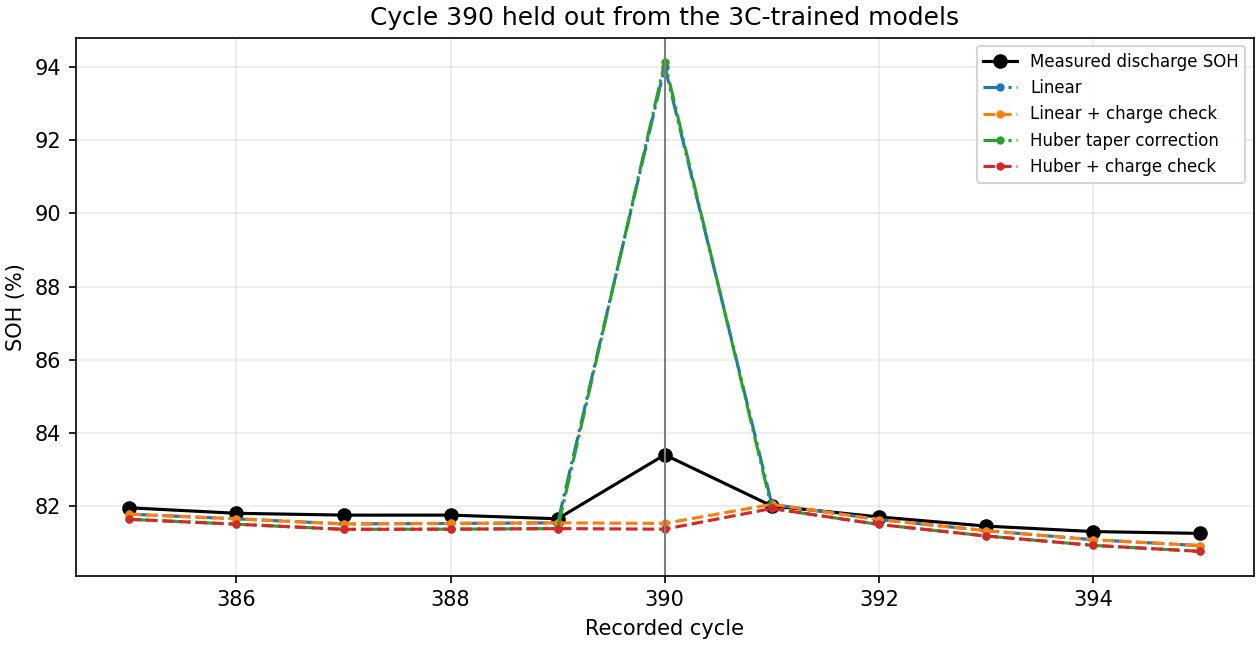

Download lifeguard_soh_reliability_results.zip from the notebook output.


In [7]:
check_guard_causality()
soh_path = locate_soh_export(INPUT_ROOT)
print(f"Reading {soh_path}")
cycles = load_cycles(soh_path)
splits, split_table = build_splits()
with threadpool_limits(limits=1):
    predictions = run_comparison(cycles, splits)
validate_predictions(cycles, splits, predictions)
scored, metrics = score_predictions(predictions)
decision, choice = assess_candidates(metrics)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
destination = OUTPUT_ROOT / "lifeguard_soh_reliability_results.zip"
config = {
    "dataset": "BatteryLife v12", "dataset_doi": "10.5281/zenodo.21149533",
    "soh_input": soh_path.name, "seed": SEED, "nominal_capacity_ah": NOMINAL_AH,
    "flag_history": HISTORY_SIZE, "flag_min_history": MIN_FLAG_HISTORY,
    "flag_mad_multiplier": MAD_MULTIPLIER, "flag_floors": FLAG_FLOORS, "fallback_count": FALLBACK_COUNT,
    "near_eol_soh_pct": NEAR_EOL_SOH, "large_error_pp": LARGE_ERROR_PP, "huber_parameters": HUBER_SETTINGS,
    "chosen_model": choice, "packages": {pkg: version(pkg) for pkg in ("numpy", "pandas", "scikit-learn", "matplotlib")},
}
with TemporaryDirectory(prefix="lifeguard_soh_reliability_", dir=OUTPUT_ROOT) as directory:
    output = Path(directory) / "results"
    output.mkdir()
    charge_audit = cycles.drop(columns=["discharge_capacity_ah", "observed_soh_pct"])
    anomaly = scored.loc[scored.cell_id.eq(OUTLIER_CELL) & scored.cycle.between(OUTLIER_CYCLE - 2, OUTLIER_CYCLE + 2)]
    for filename, table in (
        ("metrics.csv", metrics), ("predictions.csv", scored), ("charge_trace_flags.csv", charge_audit),
        ("cell_splits.csv", split_table), ("model_selection.csv", decision), ("cycle_390_comparison.csv", anomaly),
    ):
        table.to_csv(output / filename, index=False)
    (output / "run_config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
    write_summary(output / "summary.md", metrics, decision, choice, cycles, scored)
    plot_cycle_390(scored, output / "cycle_390_soh.png")
    package_results(output, destination)
    display(Markdown((output / "summary.md").read_text(encoding="utf-8")))
    display(Image(filename=str(output / "cycle_390_soh.png")))

print(f"Download {destination.name} from the notebook output.")